<div style="
    background-color: #7BAFD4;
    border-radius: 18px;
    padding: 22px 26px;
    display: flex;
    align-items: center;
    gap: 24px;
    margin-bottom: 18px;
">
    <img src="../592_avatar_lr.png" alt="GEOG 592"
        style="width:110px;height:110px;border-radius:22px;">
    <div>
        <div style="
            font-family: Impact, 'Arial Black', Arial, sans-serif;
            font-size: 42px;
            font-weight: 900;
            letter-spacing: 2px;
            line-height: 1;
            color: white;
        ">GEOG 592</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 22px;
            font-weight: 700;
            color: #13294B;
            margin-top: 8px;
        ">GIS Programming</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 16px;
            color: #13294B;
            margin-top: 6px;
        ">Cartography example legend</div>
    </div>
</div>



In [2]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

<Axes: >

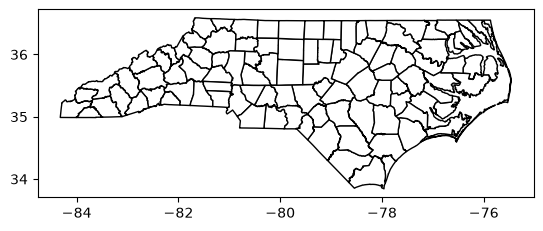

In [ ]:
# Getting the US census data.

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


# Code for county level data.

counties = gpd.read_file(url_0+url_county)
nc_counties = counties.loc[counties["STATEFP"] == "37"].copy()
nc_counties.plot(edgecolor="black", facecolor="white")

Text(0.5, 1.0, 'North Carolina Counties')

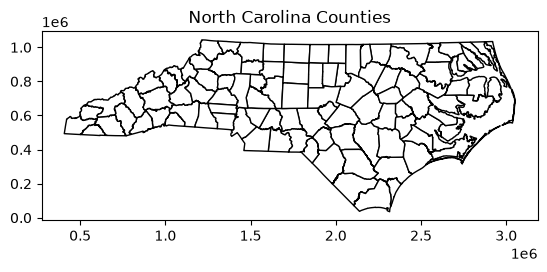

In [ ]:
# Using a local projection. 
# Units are not in degrees, now in feet. 
# Most state planes are in feet. 
ncc = nc_counties.to_crs(epsg=6543)

# plot() is part of geopandas. 
ncc.plot(edgecolor="black", facecolor="white")
plt.title("North Carolina Counties")

In [50]:
# Making a plotting function.
# Ax is the axes object we assign designs to.
def nc_plot(ax, stroke, fill):
    ncc.plot(ax=ax, edgecolor=stroke, facecolor=fill)

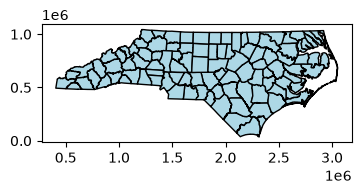

In [51]:
# Calling the function. 
# (width, height)
fig, ax = plt.subplots(figsize=(4, 2))
nc_plot(ax, "black", "lightblue")

Text(0.5, 1.06, 'County boundaries 2024')

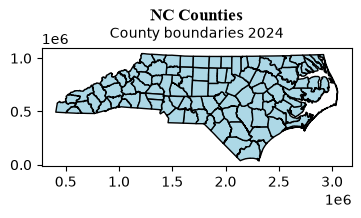

In [ ]:
# Setting and styling a title 
fig, ax = plt.subplots(figsize=(4, 2))
nc_plot(ax, "black", "lightblue")
ax.set_title("NC Counties", fontsize=12, fontweight="bold", fontname="Times New Roman", pad=20)
ax.text(0.5, 1.06, 
        "County boundaries 2024", 
        # Uses the coordinate system of the figure. 
        # Even though ncc is in the local projection, 
        # the computer stores the coordinates using a different system (a proportion). 
        transform=ax.transAxes, 
        ha='center', 
        va='bottom', 
        fontsize='10')

In [ ]:
# Demonstration of the computer coordinates vs. the projection coordinates. 
# The projection coordinates are on the axes of the plot. 
# Durham coordinates are (2036476.502 831990.237)
ncc_copy = ncc.copy()
ncc_copy["geometry"] = ncc_copy.geometry.centroid 
ncc_copy[ncc_copy['NAME'] == "Durham"]

,STATEFP,COUNTYFP,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER,geometry
1931,37,063,01008550,0500000US37063,37063,Durham,Durham County,NC,North Carolina,06,744748241,26712251,POINT (2036476.502 831990.237)


Text(2036476.502, 831990.237, 'X')

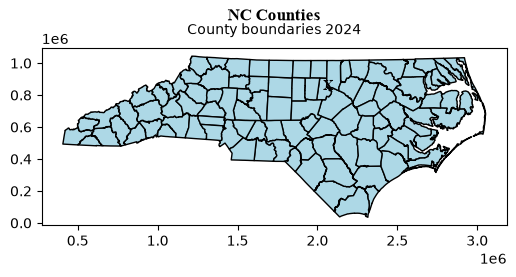

In [70]:
fig, ax = plt.subplots(figsize=(6, 3))
nc_plot(ax, "black", "lightblue")
ax.set_title("NC Counties", fontsize=12, fontweight="bold", fontname="Times New Roman", pad=20)
ax.text(0.5, 1.06, 
        "County boundaries 2024", 
        # Uses the coordinate system of the figure. 
        # Even though ncc is in the local projection, 
        # the computer stores the coordinates using a different system (a proportion). 
        transform=ax.transAxes, 
        ha='center', 
        va='bottom', 
        fontsize='10')

# Not using the state plane projection. 
ax.text(2036476.502, 831990.237, "X", fontname="Times New Roman", fontweight="bold")